In [354]:
random_variable = 1234

Path to files on server 
- example Mac file_path = "~/name/kurse/ppa/session_2/"
- example Windows file_path = "c:/users/name/kurse/session_2/"

In [355]:
file_path = "https://raw.github.com/jan-source/ppa_erp_student/main/sessions/2_session/"

### Read data

In [356]:
data_a = pd.read_csv(f"{file_path}churn_part_a.csv")

In [357]:
data_a.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0


In [358]:
data_a.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [359]:
data_b = pd.read_csv(f"{file_path}churn_part_b.csv")

In [360]:
data_b.head()

,CustomerId,Geography,Gender,Age
0,15634602,France,Female,42.0
1,15647311,Spain,Female,NaN
2,15619304,France,Female,42.0
3,15701354,France,Female,39.0
4,15737888,Spain,Female,43.0


In [361]:
data_b.dtypes

CustomerId      int64
Geography         str
Gender            str
Age           float64
dtype: object

### combine both datasets (keep only rows which exists in data_a and data_b)

In [362]:
data = pd.merge(left=data_a, right=data_b, on="CustomerId", how="inner")

In [363]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0
1,2,15647311,Hill,608,1,83807.86,1,0,1,112542.58,0,Spain,Female,NaN
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0


### Which % of customers churned

In [364]:
data["Exited"].mean()

np.float64(0.2037)

### How many rows have an NaN in any column

simulate how many rows are left when deleting rows with one empty column

In [365]:
data.dropna(axis=0).shape

(9996, 14)

In [366]:
data.shape

(10000, 14)

delete rows with one empty column

In [367]:
data = data.dropna(axis=0)

In [368]:
data.shape

(9996, 14)

delete only Rows if missing values in specific columns 
data.dropna(axis=0, subset=["Gender", "Age"])

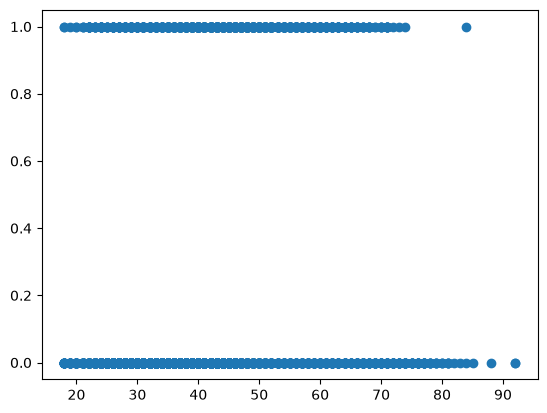

In [369]:
plt.scatter(data['Age'], data['Exited'])

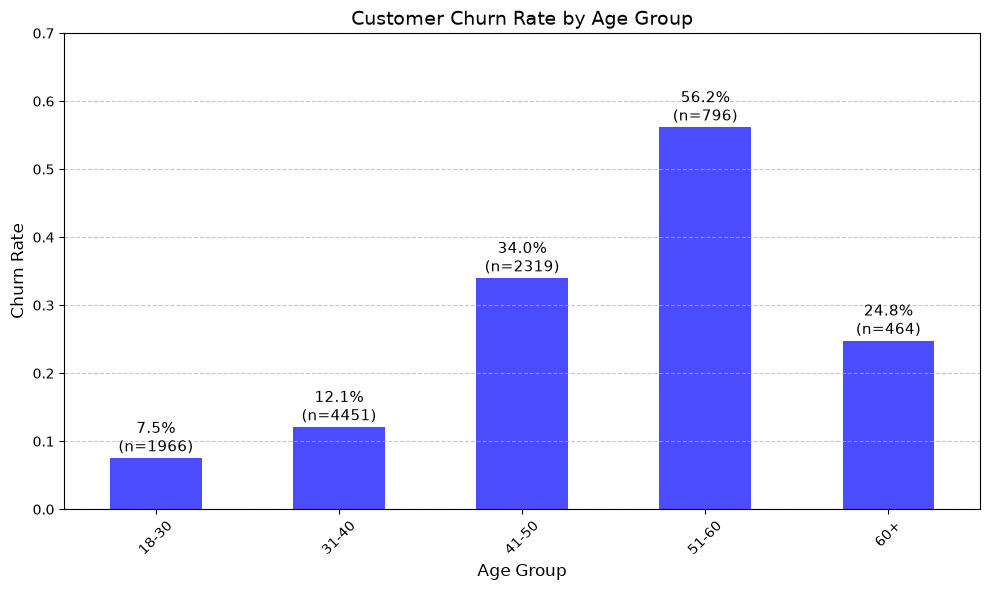

In [370]:
# Create age groups and analyze churn by age with counts
data.loc[:, 'Age_Group'] = pd.cut(
        data['Age'], 
        bins=[17, 30, 40, 50, 60, 100], 
        labels=['18-30', '31-40', '41-50', '51-60', '60+']
        )

# Calculate churn rate and counts for each age group
age_group_stats = data.groupby('Age_Group').agg(
    churn_rate=('Exited', 'mean'),
    count=('Exited', 'count')
)

# Create the bar chart
plt.figure(figsize=(10, 6))
age_group_stats['churn_rate'].plot(kind='bar', color='blue', alpha=0.7)
plt.title('Customer Churn Rate by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Churn Rate', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.ylim(0, 0.7)  # Sets y-axis to range from 0 to 0.5 (or 50%)

# Add percentage labels and counts on top of each bar
for i, (rate, count) in enumerate(zip(age_group_stats['churn_rate'], age_group_stats['count'])):
    plt.text(i, rate + 0.01, f'{rate:.1%}\n(n={count})', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

## Logistic Regression

Define Features

In [371]:
x = data[["Age", "CreditScore", "Balance", "Tenure", "IsActiveMember", "NumOfProducts", "HasCrCard"]]

Define Target

In [372]:
y = data["Exited"]

Init Model

In [373]:
log_reg_simple = LogisticRegression(random_state=random_variable)

Train Model

In [374]:
log_reg_simple.fit(x, y)

C:\Users\mammenja\Documents\Kurse\03_PPA_ERP_Student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1234
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Ausgabe Koeffizienten:

In [375]:
log_reg_simple.coef_

array([[ 4.52225945e-02, -4.71254251e-03,  3.54707106e-06,
        -6.84810189e-02, -4.41613536e-02, -2.10639173e-02,
        -8.91326282e-03]])

In [376]:
coefficients_formated =  pd.concat(
    [
     pd.Series(['Age', 'CreditScore', 'Balance']),
     pd.DataFrame(np.transpose(log_reg_simple.coef_))
    ],
     axis=1
 )

In [377]:
coefficients_formated

,0,0
0,Age,0.045223
1,CreditScore,-0.004713
2,Balance,0.000004
3,NaN,-0.068481
4,NaN,-0.044161
5,NaN,-0.021064
6,NaN,-0.008913


Calculate Predictions

Predictions 1 / 0

In [378]:
predictions = log_reg_simple.predict(x)

In [379]:
len(log_reg_simple.predict(x))

9996

For how many customers does the model predict 1 (customer leaves us)

In [380]:
sum(log_reg_simple.predict(x))

np.int64(318)

Get the probabibility for each customer that she/he leaves us 
- first value is probability for 0 (customer stays)
- second value is probability for 1 (customer leaves)

In [381]:
log_reg_simple.predict_proba(x)

array([[0.77555446, 0.22444554],
       [0.62974011, 0.37025989],
       [0.83917799, 0.16082201],
       ...,
       [0.9062685 , 0.0937315 ],
       [0.85069345, 0.14930655],
       [0.91047971, 0.08952029]], shape=(9996, 2))

## Calculate Confusion Matrix (as in Slides 39)

In [382]:
confusion_matrix(y, predictions, labels=[True, False]).T

array([[ 128,  190],
       [1908, 7770]])

Calculate accuracy by hand

In [383]:
(125 + 7674) / (125 + 286 + 1911 + 7674) 

0.7802120848339336

Use implemented sklearn function

In [384]:
accuracy_score(y, predictions)

0.7901160464185675

Calculate Precision by hand

In [385]:
125 / (125 + 286)

0.30413625304136255

Calculate Recall by hand

In [386]:
125 / (125 + 1911)

0.061394891944990176

In [387]:
accuracy_score(y, predictions)

0.7901160464185675

In [388]:
precision_score(y, predictions)

0.4025157232704403

In [389]:
recall_score(y, predictions)

0.06286836935166994

### Decision Tree for customer churn

In [390]:
clf_tree =  tree.DecisionTreeClassifier(
    random_state=random_variable, 
    max_depth=5
)

In [391]:
clf_tree.fit(x, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

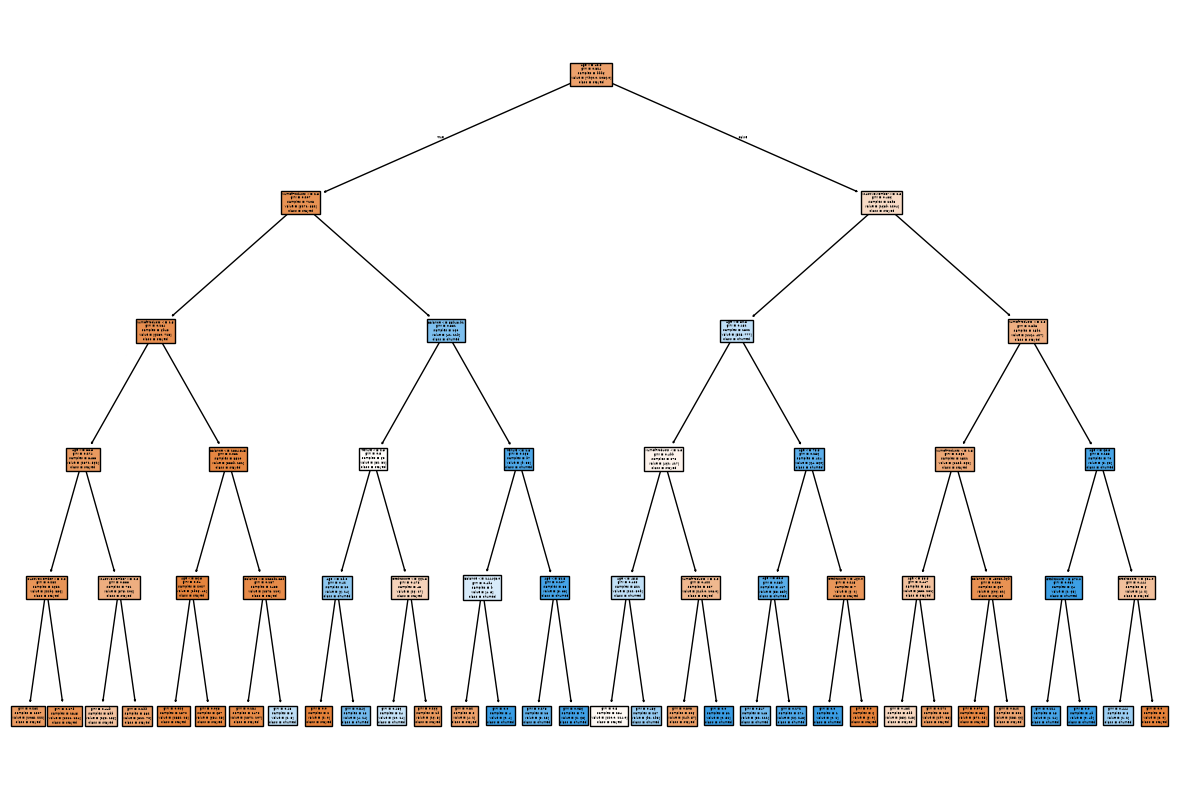

In [392]:
plt.figure(figsize = (15, 10) ) # Define Layout of Plot
tree.plot_tree(
    clf_tree,
    feature_names=x.columns,
    class_names=["stayed", "churned"],
    filled=True
)
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.show() # Show tree in defined Layout

### Predictions for Decision Tree:

In [393]:
predictions_tree = clf_tree.predict(x)

### Confusion Matrix for Decision Tree

In [394]:
confusion_matrix(y, predictions_tree, labels=[True, False]).T

array([[ 789,  173],
       [1247, 7787]])

In [395]:
accuracy_score(y, predictions_tree)

0.8579431772709084

In [396]:
precision_score(y, predictions_tree)

0.8201663201663202

In [397]:
recall_score(y, predictions_tree)

0.387524557956778

#### Encoding of Categorical Variables (Gender, Geopgraphy)

In [398]:
gender_dummies = pd.get_dummies(data['Gender'])

In [399]:
geo_dummies = pd.get_dummies(data['Geography'], prefix="geo")

In [400]:
geo_dummies.head()

,geo_France,geo_Germany,geo_Spain
0,True,False,False
2,True,False,False
3,True,False,False
4,False,False,True
5,False,False,True


### Add new columns to dataset

In [401]:
data = pd.concat([data, gender_dummies, geo_dummies], axis=1)

In [416]:
geo_dummies.columns

Index(['geo_France', 'geo_Germany', 'geo_Spain'], dtype='str')

In [427]:
data[list(gender_dummies.columns) + list(geo_dummies.columns)].head()

,Female,Male,geo_France,geo_Germany,geo_Spain
0,True,False,True,False,False
2,True,False,True,False,False
3,True,False,True,False,False
4,True,False,False,False,True
5,False,True,False,False,True


In [403]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography,Gender,Age,Age_Group,Female,Male,geo_France,geo_Germany,geo_Spain
0,1,15634602,Hargrave,619,2,0.00,1,1,1,101348.88,1,France,Female,42.0,41-50,True,False,True,False,False
2,3,15619304,Onio,502,8,159660.80,3,1,0,113931.57,1,France,Female,42.0,41-50,True,False,True,False,False
3,4,15701354,Boni,699,1,0.00,2,0,0,93826.63,0,France,Female,39.0,31-40,True,False,True,False,False
4,5,15737888,Mitchell,850,2,125510.82,1,1,1,79084.10,0,Spain,Female,43.0,41-50,True,False,False,False,True
5,6,15574012,Chu,645,8,113755.78,2,1,0,149756.71,1,Spain,Male,44.0,41-50,False,True,False,False,True


### Add male and female as features

More efficient way to generate features list

In [428]:
features = ["Age", "CreditScore", "Balance", 
          "Tenure", "IsActiveMember", 
          "NumOfProducts", "HasCrCard"] + list(geo_dummies.columns) + list(gender_dummies.columns)

In [429]:
features

['Age',
 'CreditScore',
 'Balance',
 'Tenure',
 'IsActiveMember',
 'NumOfProducts',
 'HasCrCard',
 'geo_France',
 'geo_Germany',
 'geo_Spain',
 'Female',
 'Male']

In [404]:
x = data[features]

In [405]:
clf_tree =  tree.DecisionTreeClassifier(
    random_state=random_variable, 
    max_depth=5,
    min_samples_leaf=10
)

In [406]:
clf_tree.fit(x, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

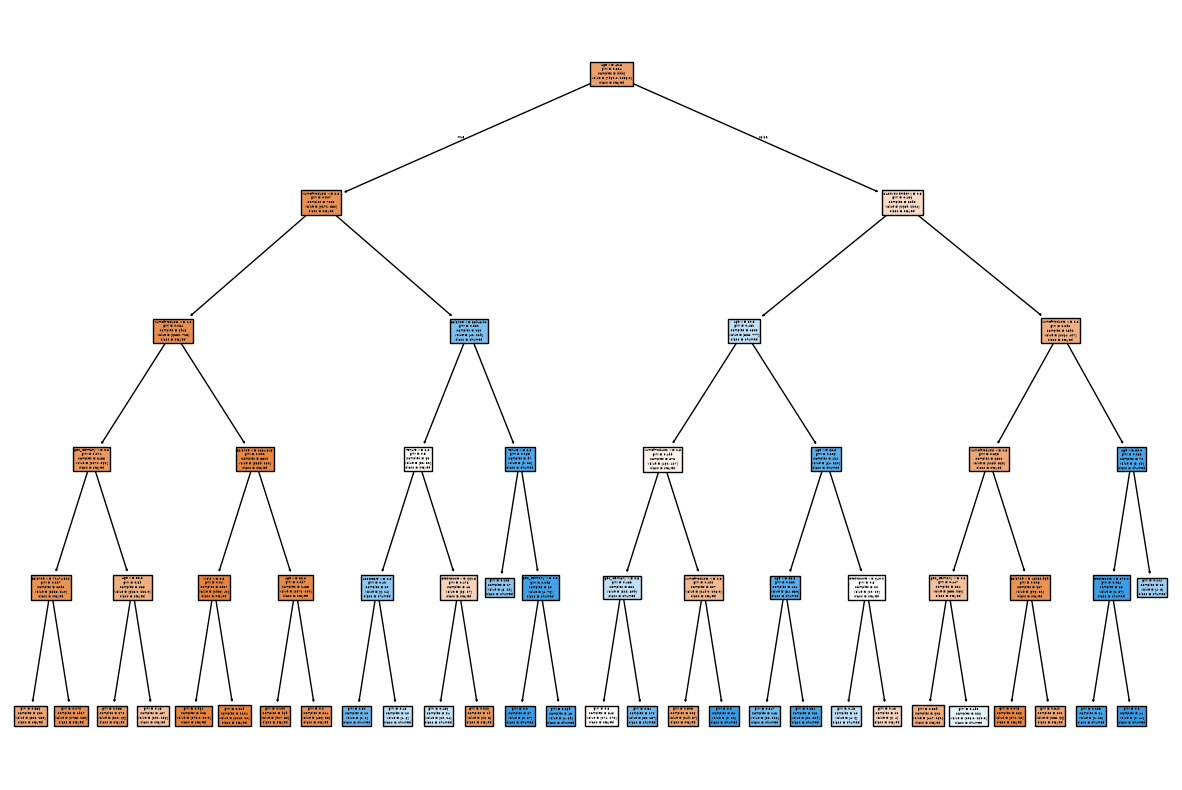

In [407]:
plt.figure(figsize = (15, 10) ) # Define Layout of Plot
tree.plot_tree(
    clf_tree,
    feature_names=x.columns,
    class_names=["stayed", "churned"],
    filled=True
)
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.show() # Show tree in defined Layout

### Changes in accurary, precision, recall

### Generate Predictions

In [408]:
predictions_complex_tree = clf_tree.predict(x)

In [409]:
accuracy_score(y, predictions_complex_tree)

0.8576430572228891

In [410]:
accuracy_score(y, predictions_tree)

0.8579431772709084

In [411]:
precision_score(y, predictions_complex_tree)

0.7845868152274837

In [412]:
precision_score(y, predictions_tree)

0.8201663201663202

In [414]:
recall_score(y, predictions_complex_tree)

0.4150294695481336

In [415]:
recall_score(y, predictions_tree)

0.387524557956778